# Подготовка данных для прогнозирования

В работе используется уже обработанный файл `data/data_clean.parquet`, полученный в результате обработки данных в прошлых дз (прикреплен вместе в дз).

Логика работы:
1. загружаем и проверяем данные;
2. обрабатываем категориальные признаки;
3. анализируем числовые признаки;
4. создаём дополнительные признаки;
5. проверяем корреляции;
6. обучаем модель на 2022 году и проверяем на 2023 году.

In [16]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

## 1. Загрузка обработанных данных


In [17]:
DATA_PATH = Path('../data') / 'data_clean.parquet'


df_pedagog_all = pd.read_parquet(DATA_PATH)
print("Размер данных:", df_pedagog_all.shape)

Размер данных: (417149, 31)


In [18]:
print("Первые строки:")
display(df_pedagog_all.head())
print("\nЦелевая переменная target:")
print(df_pedagog_all['target'].value_counts(dropna=False))

Первые строки:


,id,school_num,main_position,speciality,sex,age,academic_degree,category_qual,category_date,category_due,...,n_unique_subjects,min_parallel,max_parallel,n_unique_parallel,target,experience_age_all_clean,experience_age_pedagogic_clean,experience_age_other_clean,category_date_clean,category_due_clean
0,f583c34a49,478,Педагог дополнительного образования,не указано,0,35,нет / не указано,нет категории,NaN,NaN,...,2,2,9,3,0.0,12,1,11,NaN,NaN
1,f583c34a49,478,Педагог дополнительного образования,не указано,0,35,нет / не указано,нет категории,NaN,NaN,...,2,2,9,3,0.0,12,1,11,NaN,NaN
2,f583c34a49,478,Педагог дополнительного образования,не указано,0,35,нет / не указано,нет категории,NaN,NaN,...,2,2,9,3,0.0,12,1,11,NaN,NaN
3,f583c34a49,478,Педагог дополнительного образования,не указано,0,35,нет / не указано,нет категории,NaN,NaN,...,2,2,9,3,0.0,12,1,11,NaN,NaN
4,08ff701e26,523,Учитель,не указано,0,54,нет / не указано,нет категории,NaN,NaN,...,2,7,11,5,1.0,29,24,5,NaN,NaN



Целевая переменная target:
target
0.0    234488
NaN    149690
1.0     32971
Name: count, dtype: int64


## 2. Целевая переменная и очищенные признаки

In [19]:
# Целевая переменная и очищенные числовые признаки
df_pedagog_all['is_out_next_year'] = df_pedagog_all['target']
df_pedagog_all = df_pedagog_all.drop(columns=['target'])

clean_cols = {
    'experience_age_all_clean': 'experience_age_all',
    'experience_age_pedagogic_clean': 'experience_age_pedagogic',
    'experience_age_other_clean': 'experience_age_other',
    'category_date_clean': 'category_date',
    'category_due_clean': 'category_due',
}

for clean_col, col in clean_cols.items():
    if clean_col in df_pedagog_all.columns:
        df_pedagog_all[col] = df_pedagog_all[clean_col]

## 3. Подготовка категориальных признаков

Поле `speciality` содержит много вариантов написания.
Чтобы уменьшить число редких категорий, объединяем их в более крупные группы: учитель, воспитатель, управление, прочее

In [20]:
RULES = {
    'учитель': [
        'английского языка', 'русского языка', 'французского языка',
        'немецкого языка', 'испанского языка', 'итальянского языка',
        'китайского языка', 'арабского языка', 'родного языка',
        'родной литературы', 'литературы', 'литературного чтения',
        'истории', 'всеобщей истории', 'истории России',
        'обществознания', 'обществознания и естествознания (окружающий мир)',
        'права', 'экономики',
        'основ духовно-нравственной культуры народов России',
        'математики', 'алгебры', 'геометрии', 'физики', 'информатики',
        'математики и информатики', 'в сфере ИКТ', 'естествознания',
        'биологии', 'химии', 'географии',
        'изобразительного искусства', 'музыки', 'технологии',
        'физической культуры', 'основ безопасности жизнедеятельности',
        'начальных классов',
    ],

    'воспитатель': [
        'офицер кадетского класса', 'офицер-воспитатель кадетского класса',
        'по социальной работе',
        'по социализации, воспитанию и безопасности обучающихся',
        'по профориентации',
        'группы полного дня, группы ОВЗ', 'группы полного дня',
        'группы продленного дня', 'группы кратковременного пребывания',
        'группы ОВЗ', 'интерната, группы ОВЗ',
    ],

    'управление': [
        'по контролю качества образования', 'учебной части',
        'по содержанию образования, конвергенции образовательных программ',
        'по комплексной безопасности',
        'по материально-техническому обеспечению',
        'по управлению ресурсами', 'по питанию',
        'по финансово-экономической деятельности', 'по учету контингента',
        'по музейной работе', 'учебно-производственной мастерской',
    ],
}

In [21]:
value_to_group = {}
for group, values in RULES.items():
    for v in values:
        value_to_group[v.strip().lower()] = group


def categorize(value):
    if pd.isna(value):
        return 'не указано'
    v = str(value).strip().lower()
    return value_to_group.get(v, 'прочее')

После укрупнения категорий удаляем дубликаты по сотруднику и году.
Для моделирования оставляем только 2022 и 2023 годы, потому что для 2024 года нет готового значения целевой переменной.

In [22]:
df_pedagog_all['speciality_cat'] = df_pedagog_all['speciality'].apply(categorize)

df_pedagog_clean = df_pedagog_all.drop_duplicates(
    subset=['id', 'year'], keep='first'
).copy()

# Для моделирования нужны только строки с известной целью
df_pedagog_clean = df_pedagog_clean[
    df_pedagog_clean['year'].isin([2022, 2023]) &
    df_pedagog_clean['is_out_next_year'].notna()
].copy()

df_pedagog_clean['is_out_next_year'] = (
    df_pedagog_clean['is_out_next_year'].astype(int)
)

# Удаляем исходные текстовые и технические столбцы
cols_to_remove = [
    'academic_degree', 'main_position', 'speciality',
    'category_qual', 'subject', 'parallel',
    'experience_age_all_clean',
    'experience_age_pedagogic_clean',
    'experience_age_other_clean',
    'category_date_clean', 'category_due_clean'
]

df_pedagog_clean = df_pedagog_clean.drop(
    columns=[c for c in cols_to_remove if c in df_pedagog_clean.columns]
)

## 4. Анализ категориальных признаков

Перед кодированием смотрим частоты значений. Это нужно, чтобы:
- увидеть редкие категории;
- проверить специальные значения;
- понять, какой способ кодирования подходит каждому признаку.

In [23]:
cat_cols = [
    'main_position_cat', 'academic_degree_cat',
    'category_qual_cat', 'category_active', 'speciality_cat'
]

for col in cat_cols:
    print(f"\n{col}:")
    print(df_pedagog_clean[col].value_counts(dropna=False))


main_position_cat:
main_position_cat
учитель         34075
руководитель      379
другой            336
Name: count, dtype: int64

academic_degree_cat:
academic_degree_cat
не_найдено    34017
кандидат        768
доктор            5
Name: count, dtype: int64

category_qual_cat:
category_qual_cat
высшая        17850
первая         9431
не_найдено     7434
вторая           75
Name: count, dtype: int64

category_active:
category_active
активно       21700
не было        7964
не активно     5126
Name: count, dtype: int64

speciality_cat:
speciality_cat
прочее         18632
учитель        15879
воспитатель      157
управление       122
Name: count, dtype: int64


### Выбор кодирования

- `main_position_cat`, `speciality_cat` - номинальные признаки - One-Hot Encoding;
- `academic_degree_cat`, `category_qual_cat`, `category_active` - признаки с порядком - Ordinal Encoding;
- `school_num` - много уникальных значений - Target Encoding;
- `sex`, `class_manager` - уже бинарные, поэтому оставляем как есть.

## 5. Кодирование категориальных признаков

Сначала создаём бинарные столбцы для должности и специальности с помощью One-Hot Encoding.

In [24]:
# One-Hot Encoding
main_ohe = pd.get_dummies(
    df_pedagog_clean['main_position_cat'],
    prefix='main_position'
).astype(int)

main_ohe = main_ohe.rename(columns={
    'main_position_другой': 'main_position_other',
    'main_position_учитель': 'main_position_teacher',
    'main_position_руководитель': 'main_position_head'
})

spec_ohe = pd.get_dummies(
    df_pedagog_clean['speciality_cat'],
    prefix='speciality'
).astype(int)

spec_ohe = spec_ohe.rename(columns={
    'speciality_не указано': 'speciality_not_specified',
    'speciality_учитель': 'speciality_teacher',
    'speciality_воспитатель': 'speciality_educator',
    'speciality_управление': 'speciality_management',
    'speciality_прочее': 'speciality_other'
})

df_pedagog_clean = pd.concat(
    [df_pedagog_clean, main_ohe, spec_ohe], axis=1
)

In [25]:
print("Созданные One-Hot признаки:")
print([c for c in df_pedagog_clean.columns
       if c.startswith('main_position_') or c.startswith('speciality_')])

Созданные One-Hot признаки:
['main_position_cat', 'speciality_cat', 'main_position_other', 'main_position_head', 'main_position_teacher', 'speciality_educator', 'speciality_other', 'speciality_management', 'speciality_teacher']


In [26]:
# Ordinal Encoding
df_pedagog_clean['academic_degree_cat'] = df_pedagog_clean['academic_degree_cat'].map({
    'не_найдено': 0,
    'кандидат': 1,
    'доктор': 1
})

df_pedagog_clean['category_qual_cat'] = df_pedagog_clean['category_qual_cat'].map({
    'не_найдено': 0,
    'первая': 1,
    'вторая': 1,
    'высшая': 1
})

df_pedagog_clean['category_active'] = df_pedagog_clean['category_active'].map({
    'не было': 0,
    'не активно': 0,
    'активно': 1
})

# Исходные категориальные столбцы больше не нужны
df_pedagog_clean = df_pedagog_clean.drop(
    columns=['main_position_cat', 'speciality_cat']
)

## 6. Проверка числовых признаков

Перед масштабированием смотрим, что происходит с числовыми данными:
- `skewness` показывает, сильно ли значения смещены в одну сторону;
- `kurtosis` помогает заметить большое количество крайних значений;
- `outliers_iqr` показывает количество выбросов;
- `missing` показывает количество пропусков.



In [27]:
num_cols = [
    'experience_age_pedagogic', 'experience_age_other',
    'n_unique_subjects', 'min_parallel', 'max_parallel',
    'n_unique_parallel', 'category_date'
]

rows = []

for col in num_cols:
    x = df_pedagog_clean[col].dropna().astype(float)

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    outliers = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)

    rows.append({
        'feature': col,
        'missing': df_pedagog_clean[col].isna().sum(),
        'skewness': x.skew(),
        'kurtosis': x.kurt(),
        'outliers_iqr': outliers.sum()
    })

diagnostics = pd.DataFrame(rows)
display(diagnostics.round(3))

,feature,missing,skewness,kurtosis,outliers_iqr
0,experience_age_pedagogic,0,0.221,-0.996,2
1,experience_age_other,0,2.543,7.583,3893
2,n_unique_subjects,0,0.770,0.480,150
3,min_parallel,0,0.248,-0.589,0
4,max_parallel,0,-0.569,-1.122,0
5,n_unique_parallel,0,0.632,-0.197,0
6,category_date,7302,-1.898,6.805,819


После проверки делаем следующее:
- ограничиваем самые крайние значения педагогического стажа;
- для сильно смещённых признаков используем `log1p`, чтобы очень большие значения не влияли на модель слишком сильно;
- отрицательный дополнительный стаж заменяем на 0, потому что отрицательного стажа быть не может.


In [28]:
from scipy.stats.mstats import winsorize

# Уменьшаем влияние самых крайних значений педагогического стажа
df_pedagog_clean['experience_age_pedagogic'] = np.array(
    winsorize(
        df_pedagog_clean['experience_age_pedagogic'].values,
        limits=[0.01, 0.01]
    )
)

# Делаем сильно смещённые признаки более удобными для модели
df_pedagog_clean['n_unique_subjects'] = np.log1p(
    df_pedagog_clean['n_unique_subjects']
)

df_pedagog_clean.loc[
    df_pedagog_clean['experience_age_other'] < 0,
    'experience_age_other'
] = 0

df_pedagog_clean['experience_age_other'] = np.log1p(
    df_pedagog_clean['experience_age_other']
)

In [29]:
print("Skewness после преобразований:")
for col in ['experience_age_pedagogic', 'experience_age_other', 'n_unique_subjects']:
    print(col, round(df_pedagog_clean[col].skew(), 3))

Skewness после преобразований:
experience_age_pedagogic 0.194
experience_age_other 0.869
n_unique_subjects -0.089


## 7. Добавляем дополнительные признаки

Чтобы модель получила больше полезной информации, создаём несколько новых признаков:
- дополнительные варианты возраста и стажа;
- есть ли квалификационная категория и сколько времени с ней связано;
- сколько сотрудников работает в школе;
- средний возраст и стаж сотрудников школы;
- насколько возраст и стаж конкретного сотрудника отличаются от среднего по его школе.



In [30]:
# Дополнительные варианты возраста и стажа
df_pedagog_clean['age_sq'] = (df_pedagog_clean['age'] / 10) ** 2
df_pedagog_clean['ped_exp_sq'] = (
    df_pedagog_clean['experience_age_pedagogic'] / 10
) ** 2

# Информация о наличии и сроках квалификационной категории
df_pedagog_clean['has_category_date'] = (
    df_pedagog_clean['category_date'].notna().astype(int)
)
df_pedagog_clean['has_category_due'] = (
    df_pedagog_clean['category_due'].notna().astype(int)
)

df_pedagog_clean['category_years_since'] = np.where(
    df_pedagog_clean['category_date'].notna(),
    (df_pedagog_clean['year'] - df_pedagog_clean['category_date']).clip(lower=0),
    0
)

df_pedagog_clean['category_years_left'] = np.where(
    df_pedagog_clean['category_due'].notna(),
    (df_pedagog_clean['category_due'] - df_pedagog_clean['year']).clip(-5, 10),
    0
)

# Общие показатели школы
school = df_pedagog_clean.groupby(['year', 'school_num'])

df_pedagog_clean['school_staff_count'] = school['id'].transform('count')
df_pedagog_clean['school_mean_age'] = school['age'].transform('mean')
df_pedagog_clean['school_mean_ped_exp'] = school[
    'experience_age_pedagogic'
].transform('mean')

df_pedagog_clean['age_vs_school'] = (
    df_pedagog_clean['age'] - df_pedagog_clean['school_mean_age']
)
df_pedagog_clean['ped_exp_vs_school'] = (
    df_pedagog_clean['experience_age_pedagogic']
    - df_pedagog_clean['school_mean_ped_exp']
)

In [31]:
new_features = [
    'age_sq', 'ped_exp_sq',
    'has_category_date', 'has_category_due',
    'category_years_since', 'category_years_left',
    'school_staff_count', 'school_mean_age',
    'school_mean_ped_exp', 'age_vs_school',
    'ped_exp_vs_school'
]

display(df_pedagog_clean[new_features].head())

,age_sq,ped_exp_sq,has_category_date,has_category_due,category_years_since,category_years_left,school_staff_count,school_mean_age,school_mean_ped_exp,age_vs_school,ped_exp_vs_school
0,12.25,0.01,0,0,0.0,0.0,150,45.193333,19.786667,-10.193333,-18.786667
4,29.16,5.76,0,0,0.0,0.0,46,50.326087,22.847826,3.673913,1.152174
10,27.04,9.00,1,1,3.0,2.0,109,42.944954,17.844037,9.055046,12.155963
18,16.81,3.61,1,1,4.0,1.0,80,41.837500,16.275000,-0.837500,2.725000
24,33.64,4.41,1,1,4.0,1.0,82,47.195122,22.682927,10.804878,-1.682927


## 8. Делим данные для обучения и проверки

Используем данные по годам:
- 2022 год — обучаем
- 2023 год — проверяем


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, TargetEncoder
from sklearn.model_selection import StratifiedKFold

train = df_pedagog_clean[df_pedagog_clean['year'] == 2022].copy()
test = df_pedagog_clean[df_pedagog_clean['year'] == 2023].copy()

y_train = train['is_out_next_year']
y_test = test['is_out_next_year']

te_cols = ['school_num']

std_cols = [
    'category_qual_cat', 'n_unique_subjects',
    'n_unique_parallel', 'experience_age_pedagogic',
    'experience_age_other'
]

minmax_cols = [
    'category_active', 'min_parallel', 'max_parallel'
]

base_binary = ['sex', 'class_manager', 'academic_degree_cat']

ohe_cols = [
    c for c in train.columns
    if c.startswith('main_position_') or c.startswith('speciality_')
]

bin_cols = [c for c in base_binary if c in train.columns] + ohe_cols

base_cols = te_cols + std_cols + minmax_cols + bin_cols
X_train_base = train[base_cols].copy()

te_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

preprocessor_corr = ColumnTransformer([
    ('te', TargetEncoder(target_type='binary', smooth='auto', cv=te_cv), te_cols),
    ('std', StandardScaler(), std_cols),
    ('minmax', MinMaxScaler(), minmax_cols),
    ('bin', 'passthrough', bin_cols)
])

X_scaled = preprocessor_corr.fit_transform(X_train_base, y_train)

feature_names = (
    ['school_num_te'] + std_cols + minmax_cols + bin_cols
)

df_scaled = pd.DataFrame(X_scaled, columns=feature_names)

In [33]:
print("Train:", train.shape)
print("Test:", test.shape)
print("Доля выбывших в train:", round(y_train.mean(), 3))
print("Доля выбывших в test:", round(y_test.mean(), 3))

Train: (17396, 37)
Test: (17394, 37)
Доля выбывших в train: 0.149
Доля выбывших в test: 0.132


## 9. Проверяем связь между признаками

Строим тепловую карту, чтобы увидеть, какие признаки слишком похожи друг на друга.

Если связь между двумя признаками по модулю больше 0.85, считаем её слишком сильной и отдельно проверяем такую пару.


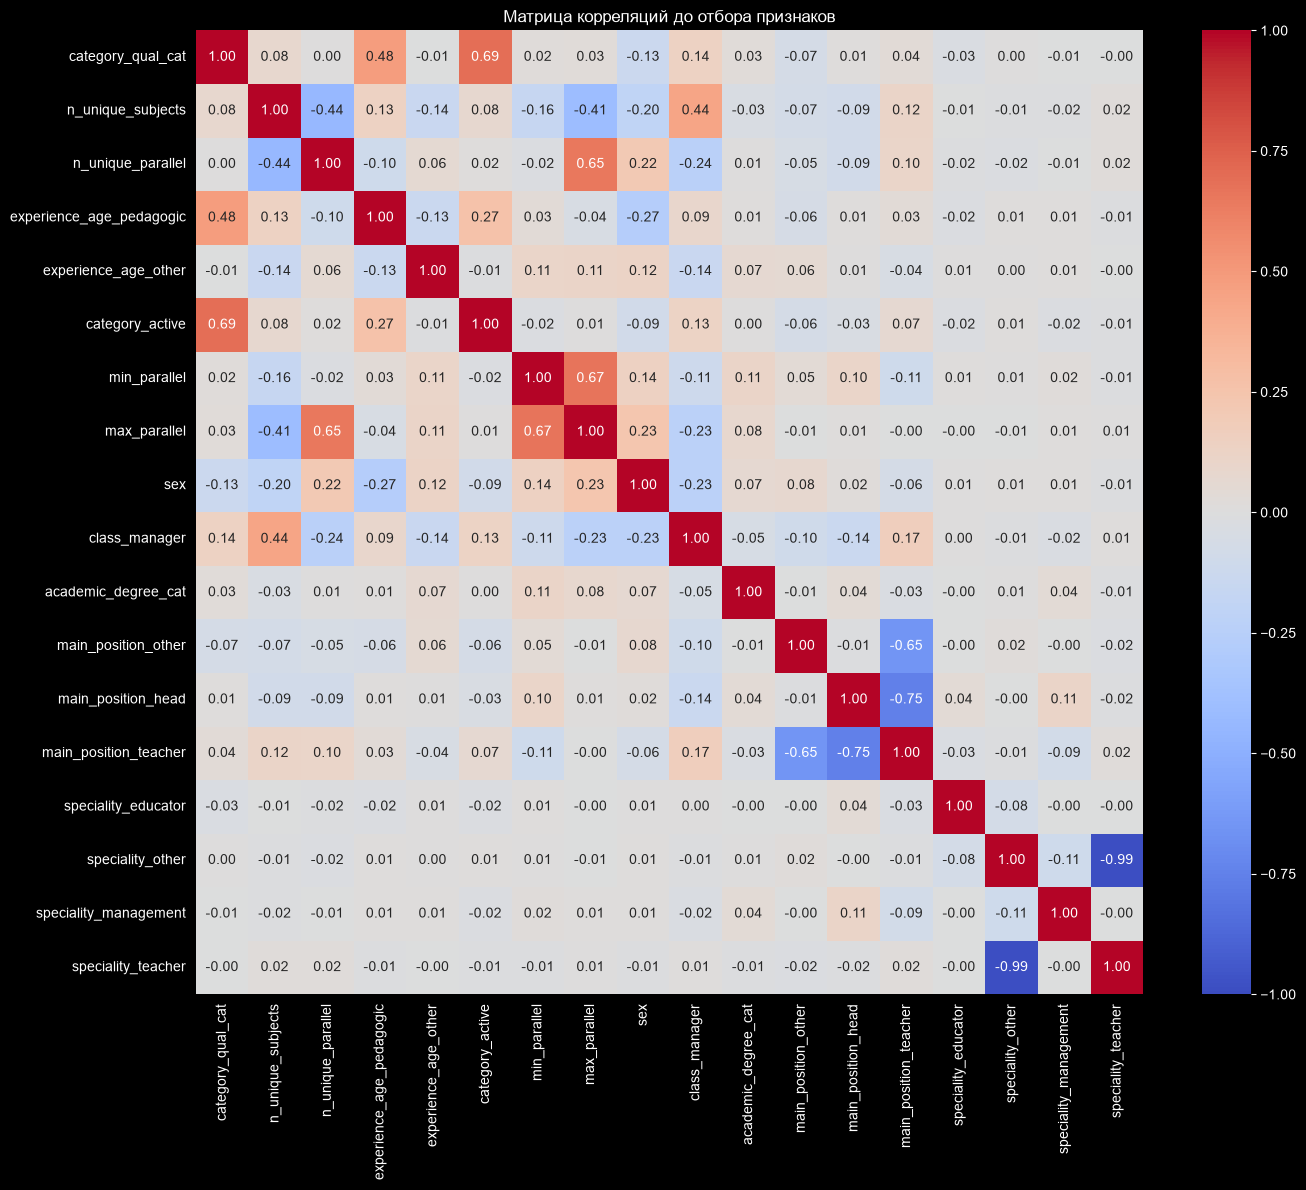

Пары с |corr| > 0.85:
('speciality_other', 'speciality_teacher', np.float64(-0.9908905715594243))


In [34]:
corr_data = df_scaled.drop(columns=['school_num_te'])
corr_matrix = corr_data.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)
plt.title('Матрица корреляций до отбора признаков')
plt.tight_layout()
plt.show()

high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        value = corr_matrix.iloc[i, j]

        if abs(value) > 0.85:
            high_corr_pairs.append((
                corr_matrix.columns[i],
                corr_matrix.columns[j],
                value
            ))

print("Пары с |corr| > 0.85:")
for pair in high_corr_pairs:
    print(pair)

## 10. Убираем признаки, которые почти повторяют друг друга

Если два One-Hot признака дают почти одинаковую информацию, оставляем только один из них.
в
После удаления ещё раз строим тепловую карту и проверяем результат.


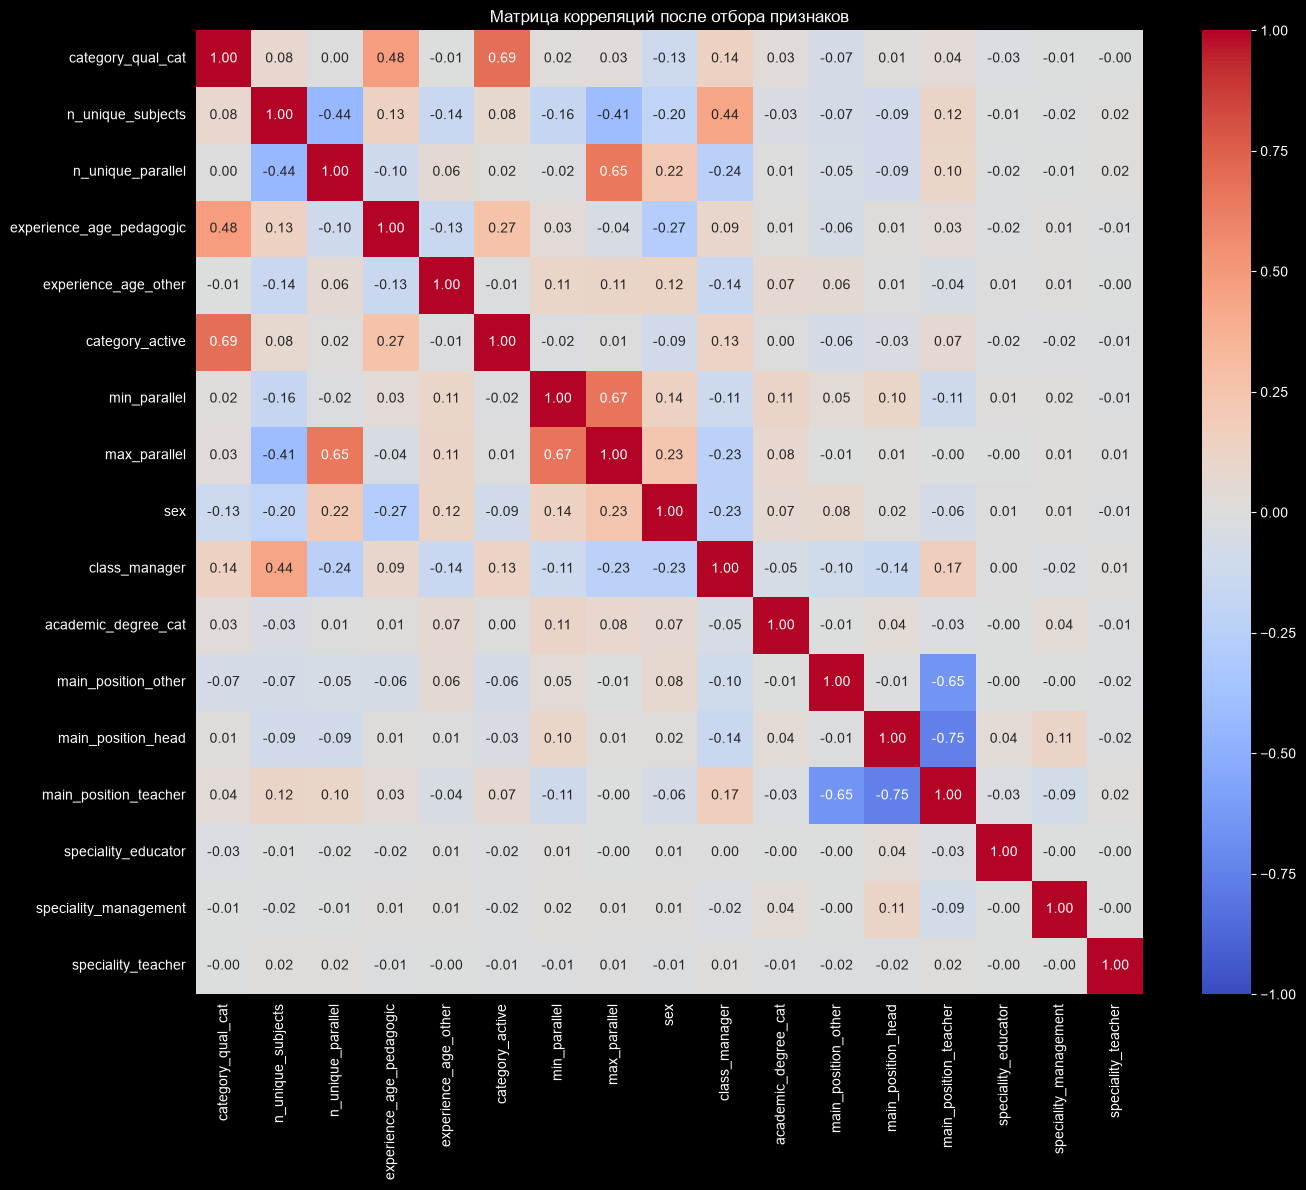

Удалены признаки: ['speciality_other']


In [35]:
# Если два One-Hot признака почти повторяют друг друга, оставляем один
cols_to_drop = []

for col1, col2, value in high_corr_pairs:
    if col1.startswith('speciality_') and col2.startswith('speciality_'):
        drop_col = (
            'speciality_not_specified'
            if 'speciality_not_specified' in {col1, col2}
            else col1
        )
    elif col1.startswith('main_position_') and col2.startswith('main_position_'):
        drop_col = col1
    else:
        continue

    if drop_col not in cols_to_drop:
        cols_to_drop.append(drop_col)

corr_after = corr_data.drop(columns=cols_to_drop, errors='ignore').corr()

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_after,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1
)
plt.title('Матрица корреляций после отбора признаков')
plt.tight_layout()
plt.show()

print("Удалены признаки:", cols_to_drop)

## 11. Обучаем итоговую модель

Здесь делаем так же, как на семинаре:

- отдельно указываем, какие признаки и как масштабировать;
- `school_num` кодируем через Target Encoding;
- обычные числовые признаки масштабируем через StandardScaler;
- признаки с небольшим понятным диапазоном — через MinMaxScaler;
- `experience_age_other` — через RobustScaler;
- бинарные признаки 0/1 оставляем без изменений;
- затем объединяем всё в `Pipeline` и обучаем логистическую регрессию.

Модель учится на данных 2022 года, а проверяется на данных 2023 года.


In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler, MinMaxScaler, RobustScaler, TargetEncoder
)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score

# Признаки для разных способов обработки
te_cols = ['school_num']

std_cols_final = [
    'category_qual_cat',
    'n_unique_subjects',
    'n_unique_parallel',
    'experience_age_pedagogic',
    'age',
    'experience_age_all',
    'age_sq',
    'ped_exp_sq',
    'school_staff_count',
    'school_mean_age',
    'school_mean_ped_exp',
    'age_vs_school',
    'ped_exp_vs_school',
    'category_years_since',
    'category_years_left'
]

minmax_cols_final = [
    'category_active',
    'min_parallel',
    'max_parallel'
]

robust_cols = ['experience_age_other']

# Оставляем только реально существующие столбцы
std_cols_final = [c for c in std_cols_final if c in train.columns]
minmax_cols_final = [c for c in minmax_cols_final if c in train.columns]
robust_cols = [c for c in robust_cols if c in train.columns]

bin_cols_final = [c for c in bin_cols if c not in cols_to_drop]
bin_cols_final += [
    'has_category_date',
    'has_category_due'
]
bin_cols_final = [c for c in bin_cols_final if c in train.columns]

model_cols = (
    te_cols
    + std_cols_final
    + minmax_cols_final
    + robust_cols
    + bin_cols_final
)

X_train = train[model_cols].copy()
X_test = test[model_cols].copy()

# Пропуски заполняем значением, рассчитанным только по данным 2022 года
for col in std_cols_final + minmax_cols_final + robust_cols:
    median = X_train[col].median()
    X_train[col] = X_train[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

# Target Encoding тоже обучается только на train
te_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

preprocessor = ColumnTransformer([
    ('te', TargetEncoder(
        target_type='binary',
        smooth='auto',
        cv=te_cv
    ), te_cols),

    ('std', StandardScaler(), std_cols_final),
    ('minmax', MinMaxScaler(), minmax_cols_final),
    ('robust', RobustScaler(), robust_cols),
    ('bin', 'passthrough', bin_cols_final)
])

pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=42
    ))
])

pipe.fit(X_train, y_train)

y_pred = pipe.predict(X_test)

y_proba = pipe.predict_proba(X_test)[:, 1]


In [37]:
print("Количество признаков модели:", len(model_cols))
print("Признаки модели:")
print(model_cols)


Количество признаков модели: 31
Признаки модели:
['school_num', 'category_qual_cat', 'n_unique_subjects', 'n_unique_parallel', 'experience_age_pedagogic', 'age', 'experience_age_all', 'age_sq', 'ped_exp_sq', 'school_staff_count', 'school_mean_age', 'school_mean_ped_exp', 'age_vs_school', 'ped_exp_vs_school', 'category_years_since', 'category_years_left', 'category_active', 'min_parallel', 'max_parallel', 'experience_age_other', 'sex', 'class_manager', 'academic_degree_cat', 'main_position_other', 'main_position_head', 'main_position_teacher', 'speciality_educator', 'speciality_management', 'speciality_teacher', 'has_category_date', 'has_category_due']


## 12. Результаты прогнозирования

После обучения проверяем модель на данных 2023 года.

Смотрим:
- Accuracy — долю правильных прогнозов
- AUC-ROC — насколько хорошо модель отличает тех, кто выбудет, от тех, кто останется
- сколько сотрудников модель отнесла к оставшимся и выбывшим
- сколько таких сотрудников было на самом деле



In [38]:
accuracy = accuracy_score(y_test, y_pred)
auc_roc = roc_auc_score(y_test, y_proba)

print(f"Accuracy модели: {accuracy:.4f}")
print(f"AUC-ROC модели: {auc_roc:.4f}")

print("\nРаспределение прогнозов:")
print(pd.Series(y_pred).value_counts().sort_index())

print("\nРеальное распределение:")
print(y_test.value_counts().sort_index())


Accuracy модели: 0.6787
AUC-ROC модели: 0.6982

Распределение прогнозов:
0    11359
1     6035
Name: count, dtype: int64

Реальное распределение:
is_out_next_year
0    15095
1     2299
Name: count, dtype: int64
